In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import Spectral_Preprocessing as sp

from argparse import ArgumentParser, Namespace
from scipy import stats

In [16]:
parser = ArgumentParser()
parser.add_argument("--range-ir-1", dest= "wn_range_ir_1", default = (948,1860))
parser.add_argument("--range-ir-2", dest= "wn_range_ir_2", default = (2698,3002))

parser.add_argument("--range-min-ir", dest= "range_min_ir", type = int, default = 400)
parser.add_argument("--range-max-ir", dest= "range_max_ir", type = int, default = 4000)
parser.add_argument("--interpolate-interval-ir", dest = "interpolate_interval_ir", type = int, default = 1) 

parser.add_argument("--finger-print-exl", dest= "finger_print_exl", type = bool, default = False)
parser.add_argument("--trans-chip", dest= "trans_chip", type = bool, default = False)

parser.add_argument("--background-rule-ir", dest= "background_rule", type = str, default = 'mean')
parser.add_argument("--threshold-mean-intensity-ir", dest= "ths_mean_int_ir", type = float, default = 0)
parser.add_argument("--threshold-total-variation-intensity-ir", dest= "ths_tot_var_int_ir", type = float, default = 0)

parser.add_argument("--range-min-raman", dest= "range_min_raman", type = float, default = 400)
parser.add_argument("--range-max-raman", dest= "range_max_raman", type = float, default = 4000)
parser.add_argument("--interpolate-interval-raman", dest = "interpolate_interval_raman", type = float, default = 1) 

parser.add_argument("--rubberband", dest="rubberband", action="store_true", default=False,)
parser.add_argument("--minmax", dest="minmax", action="store_true", default=False,)
parser.add_argument("--no-interpolate", dest = "no_interpolate", action="store_true", default = False)
parser.add_argument("--nitrogen-calibration", dest="nitrogen_calibration", action="store_true", default=True,)
parser.add_argument("--si-peak", dest= "si_peak", type = float, default = 520)

parser.add_argument("--smooth", dest = "smooth", type = int, default = 0)
parser.add_argument("--baseline", dest = "baseline", type = int, default = 5)

###Sample Code #1: Specify IR and Raman interpolation intervals along with min & max values
args: Namespace = parser.parse_args([]) ###Do not alter this section.
###PLEASE TYPE IN YOUR ARGUMENTS HERE
args.wn_range_ir_1 = (980, 1800)
args.wn_range_ir_2 = (2720, 2970)
args.range_min_ir = 675.0 #674.9918 ###enter an integer
args.range_max_ir = 4000.0 #3999.809 ###enter an integer [max value is not included]
args.interpolate_interval_ir = 2 #1.929 ###enter an integer
args.finger_print_exl = False
args.trans_chip = True
args.background_rule = 'total_var'
args.ths_mean_int_ir = 0.043
args.ths_tot_var_int_ir = 0.4543#0.59

args.range_min_raman = 355 #.555542 ###enter an integer or float #530
args.range_max_raman = 3500 #3895.935059 ##enter an integer or float [max value is not included] 
args.interpolate_interval_raman = 2.0 #168021680216802 ###enter an integer or float

args.rubberband = 'specy'#'als'#'specy' ###True for rubberband, False for iModPoly
args.minmax = 'snv' ###False for SVT normalization, True for minmax
args.no_interpolate = False ###use sample code 2 if using True for this option.
args.nitrogen_calibration = True ##True for calibration, False for no calibration.

# Mixed-Std

In [17]:
labels = pd.read_excel(open('multiview_hqi_cp/data_new/CCOPTIR_20240604_MixedMPsStdsv2_RP_mIRage_allccdata_manualsort.xlsx', 'rb'),
                  sheet_name='Other cc data and sort')# ,header=0,index_col=0

labels = labels.iloc[:,[0,9,10,11,12]].set_index('Overall ID')
labels = labels.rename({'Manual overall':'polymer'}, axis=1)


In [18]:
IR_spectra = pd.read_excel(open('multiview_hqi_cp/data_new/CCOPTIR_20240604_MixedMPsStdsv2_RP_mIRage_allccdata_manualsort.xlsx', 'rb'),
                  sheet_name='PTIR spectra',header=0)#,index_col=0

IR_spectra = IR_spectra.rename({1:'wavenumber','1.1':1},axis=1).set_index('wavenumber')

drop_cols = IR_spectra.columns[np.where(IR_spectra.iloc[1,:] == 'X value [cmâ\x81»Â¹]')[0]]
IR_spectra = IR_spectra.drop(columns=drop_cols, axis=1)#.iloc[:,drop_cols]
IR_spectra = IR_spectra.drop(IR_spectra.index[[0,1]], axis=0).T
#IR_spectra.iloc[:,:-3] = np.float64(IR_spectra.iloc[:,:-3])
IR_spectra = IR_spectra.merge(labels.iloc[:,2:3], left_index=True, right_index=True)
IR_spectra = IR_spectra.reset_index(drop=True)
IR_spectra['map_x'] = 0
IR_spectra['map_y'] = 0
IR_spectra.iloc[:,:-3] = np.float64(IR_spectra.iloc[:,:-3])

/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_16673/3727579789.py:14: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  IR_spectra.iloc[:,:-3] = np.float64(IR_spectra.iloc[:,:-3])


In [19]:
Raman_spectra = pd.read_excel(open('multiview_hqi_cp/data_new/CCOPTIR_20240604_MixedMPsStdsv2_RP_mIRage_allccdata_manualsort.xlsx', 'rb'),
                  sheet_name='Raman spectra',header=0)#,index_col=0
Raman_spectra = Raman_spectra.rename({1:'wavenumber','1.1':1},axis=1).set_index('wavenumber')
drop_cols = Raman_spectra.columns[np.where(Raman_spectra.iloc[1,:] == 'X value [cmâ\x81»Â¹]')[0]]
Raman_spectra = Raman_spectra.drop(columns=drop_cols, axis=1)
Raman_spectra = Raman_spectra.drop(Raman_spectra.index[[0,1]], axis=0).T
Raman_spectra = Raman_spectra.merge(labels.iloc[:,2:3], left_index=True, right_index=True)
Raman_spectra = Raman_spectra.reset_index(drop=True)
Raman_spectra['map_x'] = 0
Raman_spectra['map_y'] = 0
Raman_spectra.iloc[:,:-3] = np.float64(Raman_spectra.iloc[:,:-3])

/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_16673/881220063.py:11: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  Raman_spectra.iloc[:,:-3] = np.float64(Raman_spectra.iloc[:,:-3])


In [20]:
df_list = [[IR_spectra, Raman_spectra]]

In [9]:
si_peak_cal = pd.read_excel(open('multiview_hqi_cp/data_new/20240715_mIRageRaman_CalibrationLog.xlsx', 'rb'),
                  sheet_name='Si peak for PTIR files')

In [10]:
args.si_peak = np.array(si_peak_cal.query('Sample =="MPs + Standards"').iloc[:,2]) ###enter an integer or float

In [21]:
args.si_peak = [520]

In [9]:
IR_spectra = pd.read_excel(open('multiview_hqi_cp/data_new/CCOPTIR_20240604_MixedMPsStdsv2_RP_mIRage_allccdata_manualsort.xlsx', 'rb'),
                  sheet_name='PTIR spectra',header=0)#,index_col=0
IR_spectra = IR_spectra.rename({1:'1.1','1.1':1},axis=1)
idx_file_change = np.where(IR_spectra.iloc[1,:] == 'X value [cmâ\x81»Â¹]')[0]

df_list_ir = []
for i in range(idx_file_change.shape[0]):
    idx = IR_spectra.columns[idx_file_change[i]]
    if i == idx_file_change.shape[0] - 1:
        df = IR_spectra.iloc[:,idx_file_change[i]:]
    else:
        df = IR_spectra.iloc[:,idx_file_change[i]:(idx_file_change[i+1])]
        
    df = df.rename({idx:'wavenumber'},axis=1).set_index('wavenumber')
    df = df.drop(df.index[[0,1]], axis=0).T
    df = df.merge(labels.iloc[:,2:3], left_index=True, right_index=True)
    df = df.reset_index(drop=True)
    df['map_x'] = 0
    df['map_y'] = 0
    df.iloc[:,:-3] = np.float64(df.iloc[:,:-3])
    df_list_ir.append(df)
    

/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_38201/2491390523.py:20: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  df.iloc[:,:-3] = np.float64(df.iloc[:,:-3])
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_38201/2491390523.py:20: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  df.iloc[:,:-3] = np.float64(df.iloc[:,:-3])
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_38201/2491390523.py:20: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting 

In [10]:
Raman_spectra = pd.read_excel(open('multiview_hqi_cp/data_new/CCOPTIR_20240604_MixedMPsStdsv2_RP_mIRage_allccdata_manualsort.xlsx', 'rb'),
                  sheet_name='Raman spectra',header=0)#,index_col=0
Raman_spectra = Raman_spectra.rename({1:'1.1','1.1':1},axis=1)
idx_file_change = np.where(Raman_spectra.iloc[1,:] == 'X value [cmâ\x81»Â¹]')[0]

df_list_raman = []
for i in range(idx_file_change.shape[0]):
    idx = Raman_spectra.columns[idx_file_change[i]]
    if i == idx_file_change.shape[0] - 1:
        #df_list.append(Raman_spectra.iloc[:,idx_file_change[i]:])
        df = Raman_spectra.iloc[:,idx_file_change[i]:]
    else:
        #df_list.append(Raman_spectra.iloc[:,idx_file_change[i]:(idx_file_change[i+1])])
        df = Raman_spectra.iloc[:,idx_file_change[i]:(idx_file_change[i+1])]
        
    df = df.rename({idx:'wavenumber'},axis=1).set_index('wavenumber')
    df = df.drop(df.index[[0,1]], axis=0).T
    df = df.merge(labels.iloc[:,2:3], left_index=True, right_index=True)
    df = df.reset_index(drop=True)
    df['map_x'] = 0
    df['map_y'] = 0
    df.iloc[:,:-3] = np.float64(df.iloc[:,:-3])
    df_list_raman.append(df)
    

/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_38201/3677326041.py:22: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  df.iloc[:,:-3] = np.float64(df.iloc[:,:-3])
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_38201/3677326041.py:22: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  df.iloc[:,:-3] = np.float64(df.iloc[:,:-3])
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_38201/3677326041.py:22: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting 

In [22]:
raman_final, ir_final, label_list, XX_ir, XX_raman, ids, coords, _, rng, ir_bg_label, saturated_wn_list = sp.df_to_interpolated_processed_csv(args, directory_name=None, ir_export_filename=None, raman_export_filename=None, file_list = df_list, transpose = True)


/Users/eochoa/Documents/Research_Ambuj/M4AM/spectral_libraries/Spectral_Preprocessing.py:396: RuntimeWarning: invalid value encountered in scalar divide
  data4 = [(element - np.mean(data2)) / np.std(data2) for element in data2]
/Users/eochoa/Documents/Research_Ambuj/M4AM/spectral_libraries/Spectral_Preprocessing.py:187: RuntimeWarning: invalid value encountered in divide
  return (x - x.mean()) / x.std()


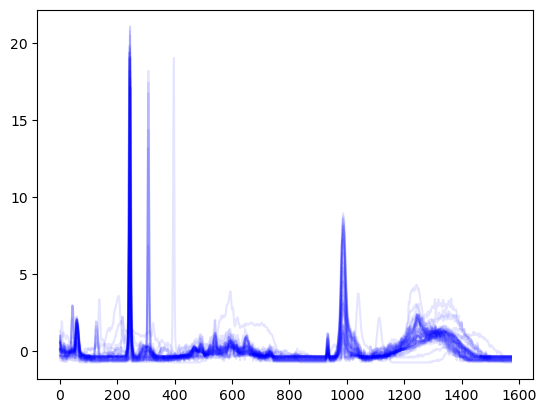

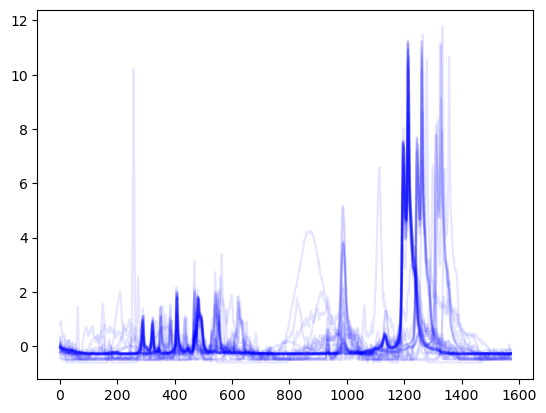

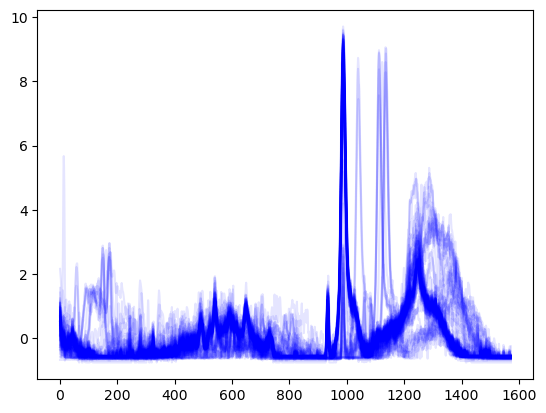

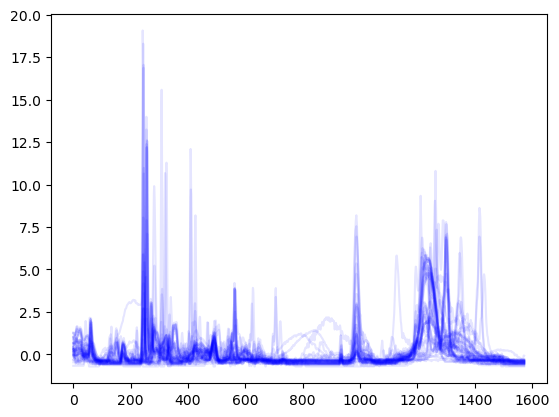

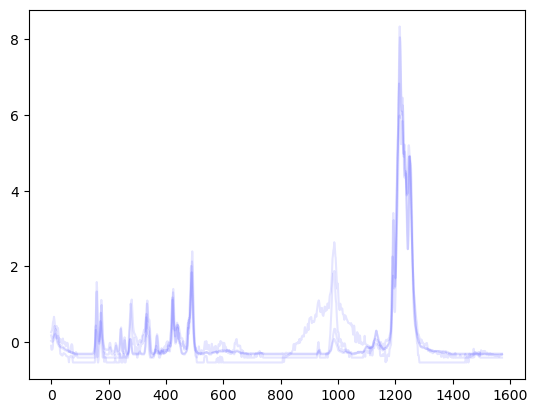

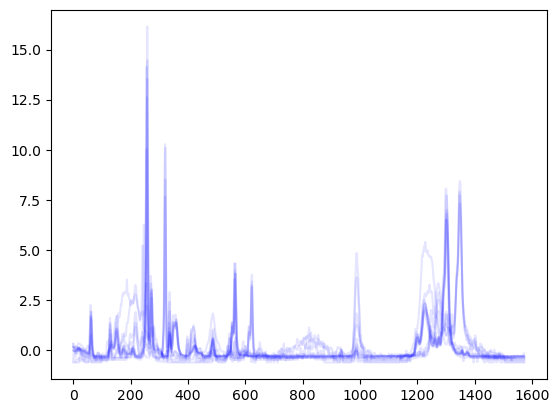

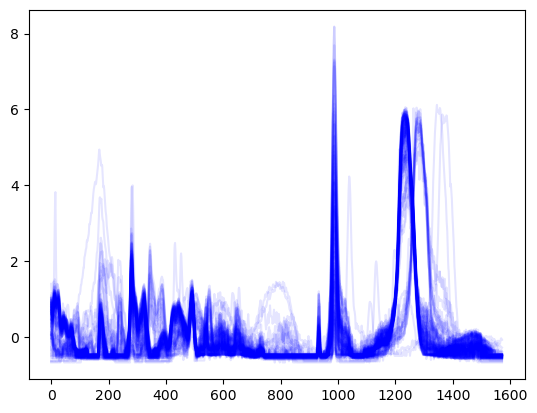

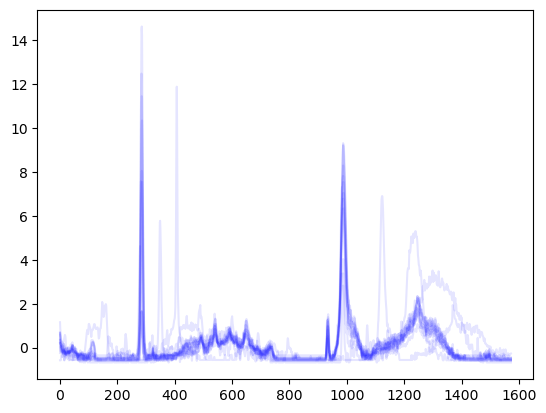

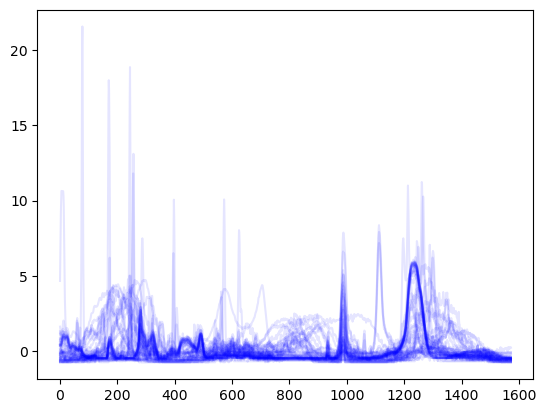

In [23]:
for p in np.unique(label_list):
    _ = plt.plot(raman_final[np.array(label_list)==p,:].T, c='b', alpha=.1)
    _ = plt.show()

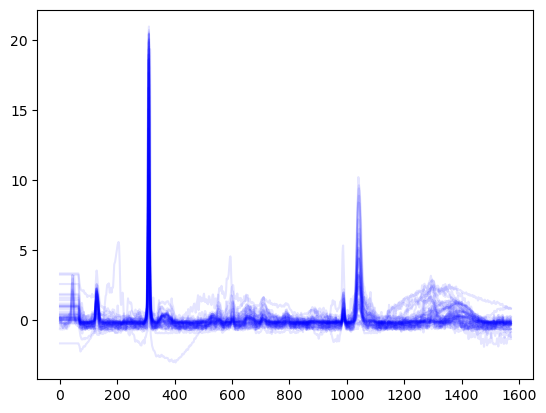

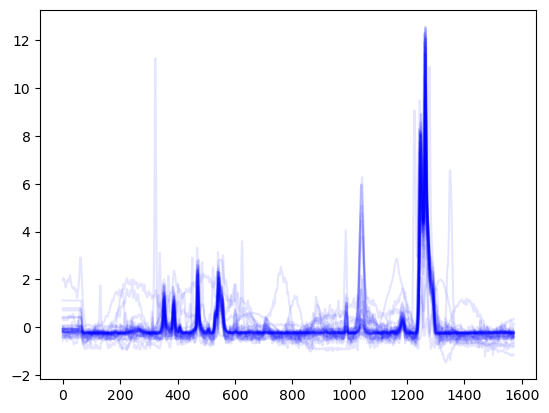

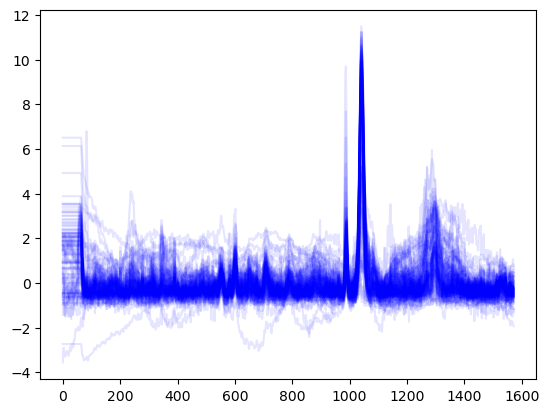

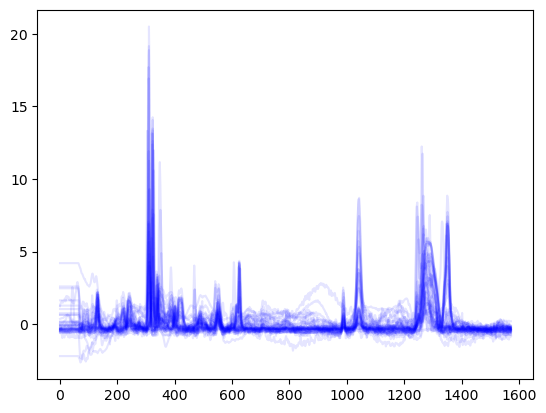

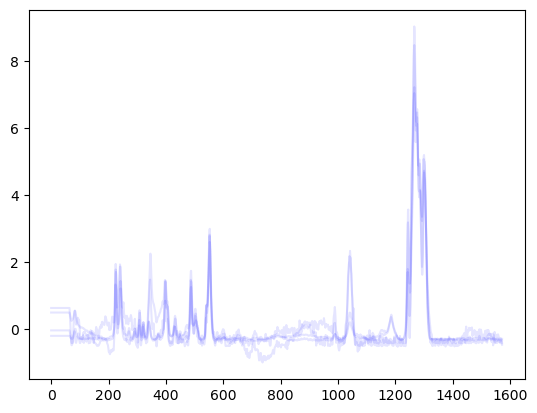

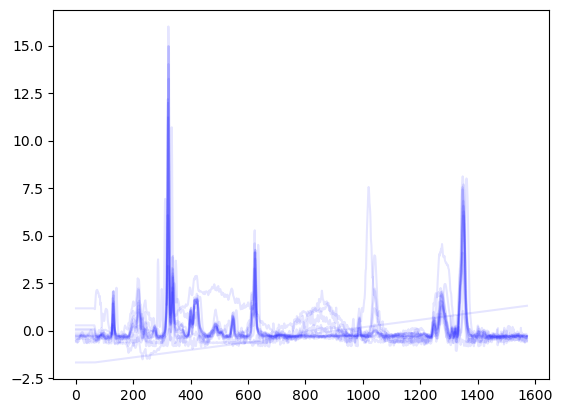

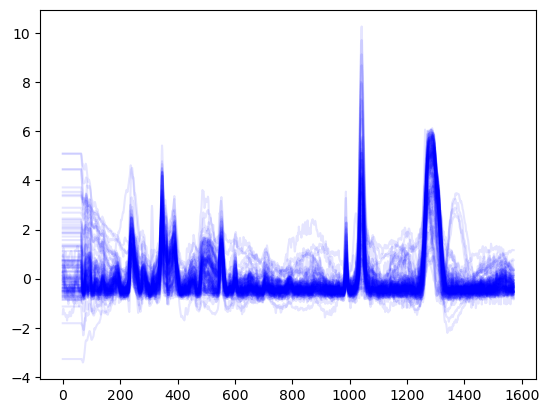

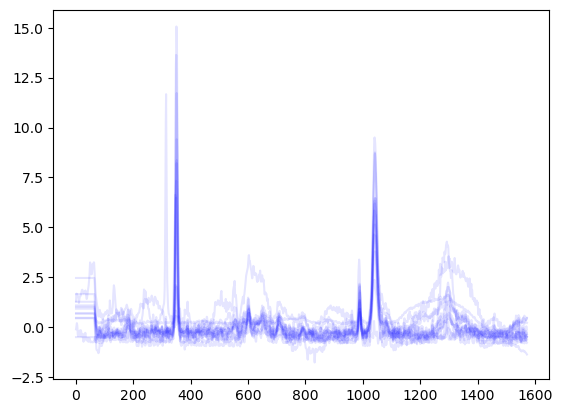

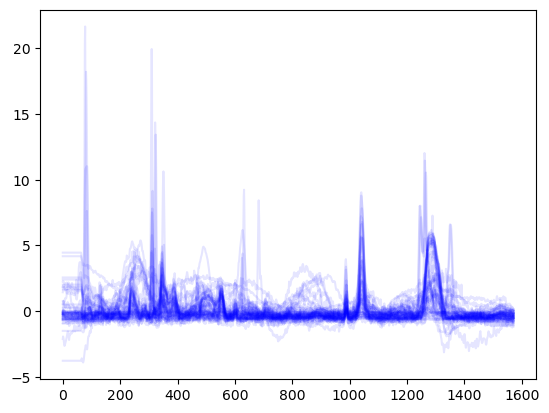

In [16]:
for p in np.unique(label_list):
    _ = plt.plot(raman_final[np.array(label_list)==p,:].T, c='b', alpha=.1)
    _ = plt.show()

In [24]:
preposs_data_raman = pd.DataFrame(raman_final)
preposs_data_raman.columns = XX_raman
preposs_data_raman = pd.concat([preposs_data_raman, coords], axis=1)
preposs_data_raman['polymer'] = label_list
preposs_data_raman['id'] = list(range(1,preposs_data_raman.shape[0]+1))
preposs_data_raman.to_csv('multiview_hqi_cp/processed_data_new/data_raman_mix_std_rebecca_pre_cal.csv')
preposs_data_raman

,355.0,357.0,359.0,361.0,363.0,365.0,367.0,369.0,371.0,373.0,...,3489.0,3491.0,3493.0,3495.0,3497.0,3499.0,map_x,map_y,polymer,id
0,0.091705,0.118524,0.100023,0.071258,0.041497,0.005297,-0.043126,-0.041707,-0.008317,0.016656,...,-0.455759,-0.455759,-0.455759,-0.455759,-0.455759,-0.455759,0,0,AS,1
1,0.254277,0.346933,0.396195,0.427638,0.367257,0.274364,0.119755,0.085389,0.128150,0.105357,...,-0.567356,-0.567356,-0.567356,-0.567356,-0.567356,-0.567356,0,0,SCR,2
2,0.522431,0.646568,0.741623,0.816767,0.739759,0.626599,0.444810,0.425417,0.510190,0.537802,...,-0.620195,-0.620195,-0.620195,-0.620195,-0.620195,-0.620195,0,0,LOW,3
3,0.293851,0.420061,0.381838,0.307901,0.247659,0.212037,0.223150,0.225364,0.221869,0.260457,...,-0.633416,-0.633416,-0.633416,-0.633416,-0.633416,-0.633416,0,0,LOW,4
4,0.749110,0.802576,0.875867,0.947264,0.946531,0.884165,0.704803,0.550498,0.412265,0.553286,...,-0.598984,-0.598984,-0.598984,-0.598984,-0.598984,-0.598984,0,0,LOW,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
424,-0.080596,-0.094170,-0.099588,-0.103040,-0.104966,-0.107535,-0.111325,-0.118914,-0.128940,-0.136687,...,-0.128316,-0.130841,-0.134406,-0.139658,-0.142748,-0.144650,0,0,LDPE,425
425,1.254696,0.810595,0.678873,0.608288,0.435408,0.328754,0.347814,0.378054,0.415465,0.319191,...,-0.569295,-0.569295,-0.569295,-0.569295,-0.569295,-0.569295,0,0,LOW,426
426,0.842427,0.705488,0.641565,0.591392,0.511148,0.460444,0.465813,0.527701,0.625840,0.699336,...,-0.580355,-0.580355,-0.580355,-0.580355,-0.580355,-0.580355,0,0,SCR,427
427,-0.033126,-0.045912,-0.052366,-0.057641,-0.065660,-0.072877,-0.078575,-0.077726,-0.072676,-0.074620,...,-0.236725,-0.238516,-0.240201,-0.241710,-0.243508,-0.245463,0,0,LDPE,428


In [18]:
preposs_data_ir = pd.DataFrame(ir_final)
preposs_data_ir.columns = XX_ir
preposs_data_ir = pd.concat([preposs_data_ir, coords], axis=1)
preposs_data_ir['polymer'] = label_list
preposs_data_ir['id'] = list(range(1,preposs_data_raman.shape[0]+1))#pol_table.iloc[ids,:].reset_index(drop=True)
preposs_data_ir['background'] = ir_bg_label
preposs_data_ir.to_csv('multiview_hqi_cp/processed_data_new/data_ir_mix_std_rebecca.csv')
preposs_data_ir

,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2961.0,2963.0,2965.0,2967.0,2969.0,map_x,map_y,polymer,id,background
0,-0.828293,-0.758405,-0.726251,-0.765111,-0.770808,-0.728753,-0.727293,-0.757429,-0.730070,-0.732946,...,2.302543,2.214807,2.162075,2.214848,2.194427,0,0,AS,1,no_background
1,-0.163192,-0.074564,-0.230509,-0.292448,-0.220771,0.011111,0.144867,-0.239115,-0.418914,-0.141851,...,1.021715,1.338204,1.349816,0.964838,0.918447,0,0,SCR,2,no_background
2,-0.438056,0.933417,2.150888,2.177525,0.860700,0.452132,-0.315118,-1.185153,-0.967110,-0.651419,...,-8.767647,-5.406181,-1.714433,1.018770,2.725846,0,0,LOW,3,background
3,1.638889,0.455108,-0.441436,-0.560524,-1.166359,-1.748550,-1.613215,-1.766743,-1.025346,0.141626,...,2.818375,-0.981516,-1.059169,1.408004,2.597168,0,0,LOW,4,no_background
4,0.205335,1.241631,0.875970,-0.050083,-0.290827,0.486683,0.731929,0.275573,0.824066,0.533222,...,-4.550883,-4.196163,0.931492,0.827264,-0.205617,0,0,LOW,5,background
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
424,-0.373516,-0.376575,-0.377634,-0.371173,-0.377284,-0.377095,-0.369783,-0.372860,-0.377227,-0.376942,...,0.259404,0.178226,0.087044,0.011794,-0.051611,0,0,LDPE,425,no_background
425,0.292612,1.338728,0.671795,-0.383573,0.609145,1.037086,0.503721,-0.399152,-0.734338,-0.374284,...,-4.569248,-2.998487,1.186441,6.442037,1.190010,0,0,LOW,426,background
426,-0.069403,-0.123240,-0.263766,-0.277517,-0.033042,0.268466,0.312587,0.225755,-0.073730,-0.459947,...,0.266987,0.372709,1.665123,2.018124,2.487920,0,0,SCR,427,no_background
427,-0.275073,-0.273339,-0.274917,-0.276279,-0.275879,-0.275556,-0.274775,-0.275425,-0.276779,-0.276364,...,-0.202991,-0.215388,-0.224707,-0.234312,-0.243280,0,0,LDPE,428,no_background


# Mixed

In [3]:
labels = pd.read_excel(open('multiview_hqi_cp/data_new/CCOPTIR_20240326_MixedMPsv7.3_RP_mIRage_allccdata_manualsort.xlsx', 'rb'),
                  sheet_name='Other cc data and sort')# ,header=0,index_col=0

labels = labels.iloc[:,[0,9,10,11,12]].set_index('Overall ID')
labels = labels.rename({'Manual overall':'polymer'}, axis=1)

IR_spectra = pd.read_excel(open('multiview_hqi_cp/data_new/CCOPTIR_20240326_MixedMPsv7.3_RP_mIRage_allccdata_manualsort.xlsx', 'rb'),
                  sheet_name='PTIR spectra',header=0)#,index_col=0

IR_spectra = IR_spectra.rename({1:'wavenumber','1.1':1},axis=1).set_index('wavenumber')

drop_cols = IR_spectra.columns[np.where(IR_spectra.iloc[1,:] == 'X value [cmâ\x81»Â¹]')[0]]
IR_spectra = IR_spectra.drop(columns=drop_cols, axis=1)#.iloc[:,drop_cols]
IR_spectra = IR_spectra.drop(IR_spectra.index[[0,1]], axis=0).T
#IR_spectra.iloc[:,:-3] = np.float64(IR_spectra.iloc[:,:-3])
IR_spectra = IR_spectra.merge(labels.iloc[:,2:3], left_index=True, right_index=True)
IR_spectra = IR_spectra.reset_index(drop=True)
IR_spectra['map_x'] = 0
IR_spectra['map_y'] = 0
IR_spectra.iloc[:,:-3] = np.float64(IR_spectra.iloc[:,:-3])

/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_71422/2208623882.py:20: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  IR_spectra.iloc[:,:-3] = np.float64(IR_spectra.iloc[:,:-3])


In [4]:
Raman_spectra = pd.read_excel(open('multiview_hqi_cp/data_new/CCOPTIR_20240326_MixedMPsv7.3_RP_mIRage_allccdata_manualsort.xlsx', 'rb'),
                  sheet_name='Raman spectra',header=0)#,index_col=0
Raman_spectra = Raman_spectra.rename({1:'wavenumber','1.1':1},axis=1).set_index('wavenumber')
drop_cols = Raman_spectra.columns[np.where(Raman_spectra.iloc[1,:] == 'X value [cmâ\x81»Â¹]')[0]]
Raman_spectra = Raman_spectra.drop(columns=drop_cols, axis=1)
Raman_spectra = Raman_spectra.drop(Raman_spectra.index[[0,1]], axis=0).T
Raman_spectra = Raman_spectra.merge(labels.iloc[:,2:3], left_index=True, right_index=True)
Raman_spectra = Raman_spectra.reset_index(drop=True)
Raman_spectra['map_x'] = 0
Raman_spectra['map_y'] = 0
Raman_spectra.iloc[:,:-3] = np.float64(Raman_spectra.iloc[:,:-3])

/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_71422/162395748.py:11: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  Raman_spectra.iloc[:,:-3] = np.float64(Raman_spectra.iloc[:,:-3])


In [5]:
df_list = [[IR_spectra, Raman_spectra]]

In [6]:
raman_final, ir_final, label_list, XX_ir, XX_raman, ids, coords, _, rng, ir_bg_label, saturated_wn_list = sp.df_to_interpolated_processed_csv(args, directory_name=None, ir_export_filename=None, raman_export_filename=None, file_list = df_list, transpose = True)


In [7]:
preposs_data_raman = pd.DataFrame(raman_final)
preposs_data_raman.columns = XX_raman
preposs_data_raman = pd.concat([preposs_data_raman, coords], axis=1)
preposs_data_raman['polymer'] = label_list
preposs_data_raman['id'] = list(range(1,preposs_data_raman.shape[0]+1))#pol_table.iloc[ids,:].reset_index(drop=True)
preposs_data_raman.to_csv('multiview_hqi_cp/processed_data_new/data_raman_mix_rebecca.csv')
preposs_data_raman

,355.0,357.0,359.0,361.0,363.0,365.0,367.0,369.0,371.0,373.0,...,3489.0,3491.0,3493.0,3495.0,3497.0,3499.0,map_x,map_y,polymer,id
0,-0.501041,-0.519682,-0.542868,-0.564795,-0.560804,-0.557661,-0.556127,-0.565408,-0.581627,-0.579871,...,0.039946,-0.038618,-0.097014,-0.122674,-0.136031,-0.142627,0,0,PSL,1
1,1.175273,1.050172,0.918820,0.794381,0.764514,0.731451,0.692321,0.666877,0.650212,0.604536,...,-0.415735,-0.464039,-0.510675,-0.554607,-0.556132,-0.534356,0,0,PP,2
2,-0.383526,-0.418589,-0.372812,-0.318694,-0.376101,-0.416553,-0.424819,-0.428996,-0.430550,-0.430798,...,-0.345336,-0.298584,-0.247563,-0.189612,-0.220680,-0.300660,0,0,UNS,3
3,-0.283177,-0.284831,-0.280978,-0.277626,-0.294026,-0.298074,-0.278674,-0.279601,-0.293567,-0.302191,...,-0.333582,-0.329006,-0.330841,-0.343080,-0.344212,-0.339242,0,0,LDPE,4
4,-0.328164,-0.335905,-0.367911,-0.400420,-0.376702,-0.356557,-0.343191,-0.339639,-0.342380,-0.343717,...,-0.225227,-0.255764,-0.274144,-0.272795,-0.263178,-0.249018,0,0,PP,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
670,0.937842,0.892105,0.845971,0.791710,0.646078,0.535383,0.491007,0.494206,0.527921,0.558940,...,-0.477490,-0.408526,-0.378033,-0.409985,-0.517477,-0.666476,0,0,LOW,671
671,-1.711232,-1.603254,-1.581217,-1.578862,-1.580921,-1.610406,-1.691951,-1.670999,-1.584300,-1.544271,...,-0.450183,-0.493376,-0.512506,-0.492576,-0.496944,-0.514662,0,0,LDPE,672
672,0.081272,0.049941,0.019735,-0.008889,-0.022399,-0.031940,-0.033945,-0.005316,0.042963,0.027557,...,1.194519,1.272628,1.324651,1.334334,1.315598,1.281247,0,0,LOW,673
673,1.379748,1.340703,1.244280,1.143484,1.139451,1.093981,0.969851,0.888670,0.835036,1.023985,...,-0.481481,-0.450946,-0.455260,-0.516137,-0.422133,-0.243029,0,0,LOW,674


In [8]:
preposs_data_ir = pd.DataFrame(ir_final)
preposs_data_ir.columns = XX_ir
preposs_data_ir = pd.concat([preposs_data_ir, coords], axis=1)
preposs_data_ir['polymer'] = label_list
preposs_data_ir['id'] = list(range(1,preposs_data_raman.shape[0]+1))#pol_table.iloc[ids,:].reset_index(drop=True)
preposs_data_ir['background'] = ir_bg_label
preposs_data_ir.to_csv('multiview_hqi_cp/processed_data_new/data_ir_mix_rebecca.csv')
preposs_data_ir

,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2961.0,2963.0,2965.0,2967.0,2969.0,map_x,map_y,polymer,id,background
0,-0.537903,-0.720536,-0.441265,-0.282252,-0.375405,-0.489999,-0.588893,-0.612807,-0.520641,-0.552726,...,0.953232,1.216122,0.848395,-0.024958,-0.113795,0,0,PSL,1,no_background
1,-0.379507,-0.376786,-0.383757,-0.368887,-0.398953,-0.466828,-0.452727,-0.416306,-0.420293,-0.395970,...,3.644791,3.463174,2.796568,2.246403,1.725185,0,0,PP,2,no_background
2,-1.140934,-1.127009,-1.126079,-1.128619,-1.124483,-1.111299,-1.096483,-1.045484,-0.978234,-0.959911,...,1.428718,1.163827,0.817065,0.547720,0.206791,0,0,UNS,3,no_background
3,-0.257508,-0.260172,-0.259277,-0.258010,-0.256988,-0.255767,-0.253283,-0.249995,-0.248505,-0.249813,...,0.087783,0.094260,0.088447,0.084240,0.086151,0,0,LDPE,4,no_background
4,-1.291803,-1.272872,-1.263297,-1.270282,-1.255362,-1.230510,-1.219091,-1.199638,-1.163798,-1.138836,...,1.842517,1.526310,1.197150,0.900255,0.602894,0,0,PP,5,no_background
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
670,-1.266498,-0.744250,0.136157,0.405783,0.202394,0.657716,-0.954895,-1.939645,-0.688434,-0.088004,...,1.613052,-3.365680,-3.558008,-2.525450,-4.459237,0,0,LOW,671,background
671,-0.272100,-0.111010,0.347726,0.264732,-0.295118,-0.587074,-0.586101,-0.541215,-0.342822,0.241844,...,-1.735610,-2.288871,0.620977,2.340630,1.588070,0,0,LDPE,672,no_background
672,-0.411977,-0.844488,-1.272098,-0.125799,1.362316,1.341304,0.544450,0.474795,0.950098,1.204470,...,4.148223,0.802739,1.904850,3.819094,0.286300,0,0,LOW,673,background
673,1.563800,2.373778,1.001517,-0.815010,-0.908131,-0.364108,0.143371,0.013217,0.348712,1.033327,...,2.315686,6.533899,5.162165,2.214550,6.336021,0,0,LOW,674,no_background


# Ambient

In [9]:
labels = pd.read_excel(open('multiview_hqi_cp/data_new/CCOPTIR_20240716_AmbientandMPsv1_RP_mIRage_allccdata_manualsort_firstlookplots2.xlsx', 'rb'),
                  sheet_name='Other cc data and sort')# ,header=0,index_col=0

labels = labels.iloc[:,[0,9,10,11,12]].set_index('Overall ID')
labels = labels.rename({'Manual overall':'polymer'}, axis=1)

IR_spectra = pd.read_excel(open('multiview_hqi_cp/data_new/CCOPTIR_20240716_AmbientandMPsv1_RP_mIRage_allccdata_manualsort_firstlookplots2.xlsx', 'rb'),
                  sheet_name='PTIR spectra',header=0)#,index_col=0

IR_spectra = IR_spectra.rename({1:'wavenumber','1.1':1},axis=1).set_index('wavenumber')

drop_cols = IR_spectra.columns[np.where(IR_spectra.iloc[1,:] == 'X value [cmâ\x81»Â¹]')[0]]
IR_spectra = IR_spectra.drop(columns=drop_cols, axis=1)#.iloc[:,drop_cols]
IR_spectra = IR_spectra.drop(IR_spectra.index[[0,1]], axis=0).T
#IR_spectra.iloc[:,:-3] = np.float64(IR_spectra.iloc[:,:-3])
IR_spectra = IR_spectra.merge(labels.iloc[:,2:3], left_index=True, right_index=True)
IR_spectra = IR_spectra.reset_index(drop=True)
IR_spectra['map_x'] = 0
IR_spectra['map_y'] = 0
IR_spectra.iloc[:,:-3] = np.float64(IR_spectra.iloc[:,:-3])

/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_71422/2677558662.py:20: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  IR_spectra.iloc[:,:-3] = np.float64(IR_spectra.iloc[:,:-3])


In [10]:
Raman_spectra = pd.read_excel(open('multiview_hqi_cp/data_new/CCOPTIR_20240716_AmbientandMPsv1_RP_mIRage_allccdata_manualsort_firstlookplots2.xlsx', 'rb'),
                  sheet_name='Raman spectra',header=0)#,index_col=0
Raman_spectra = Raman_spectra.rename({1:'wavenumber','1.1':1},axis=1).set_index('wavenumber')
drop_cols = Raman_spectra.columns[np.where(Raman_spectra.iloc[1,:] == 'X value [cmâ\x81»Â¹]')[0]]
Raman_spectra = Raman_spectra.drop(columns=drop_cols, axis=1)
Raman_spectra = Raman_spectra.drop(Raman_spectra.index[[0,1]], axis=0).T
Raman_spectra = Raman_spectra.merge(labels.iloc[:,2:3], left_index=True, right_index=True)
Raman_spectra = Raman_spectra.reset_index(drop=True)
Raman_spectra['map_x'] = 0
Raman_spectra['map_y'] = 0
Raman_spectra.iloc[:,:-3] = np.float64(Raman_spectra.iloc[:,:-3])

/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_71422/3558368215.py:11: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  Raman_spectra.iloc[:,:-3] = np.float64(Raman_spectra.iloc[:,:-3])


In [11]:
df_list = [[IR_spectra, Raman_spectra]]

In [12]:
raman_final, ir_final, label_list, XX_ir, XX_raman, ids, coords, _, rng, ir_bg_label, saturated_wn_list = sp.df_to_interpolated_processed_csv(args, directory_name=None, ir_export_filename=None, raman_export_filename=None, file_list = df_list, transpose = True)


In [13]:
preposs_data_raman = pd.DataFrame(raman_final)
preposs_data_raman.columns = XX_raman
preposs_data_raman = pd.concat([preposs_data_raman, coords], axis=1)
preposs_data_raman['polymer'] = label_list
preposs_data_raman['id'] = list(range(1,preposs_data_raman.shape[0]+1))#pol_table.iloc[ids,:].reset_index(drop=True)
preposs_data_raman.to_csv('multiview_hqi_cp/processed_data_new/data_raman_amb_rebecca.csv')
preposs_data_raman

,355.0,357.0,359.0,361.0,363.0,365.0,367.0,369.0,371.0,373.0,...,3489.0,3491.0,3493.0,3495.0,3497.0,3499.0,map_x,map_y,polymer,id
0,-0.245323,-0.245323,-0.245323,-0.245323,-0.245323,-0.245323,-0.245323,-0.245323,-0.245323,-0.245323,...,-0.179815,-0.174843,-0.176212,-0.180087,-0.186633,-0.189791,0,0,PSL,1
1,-0.198094,-0.198094,-0.198094,-0.198094,-0.198094,-0.198094,-0.198094,-0.198094,-0.198094,-0.198094,...,-0.463190,-0.456612,-0.416388,-0.391933,-0.384291,-0.366689,0,0,AMB,2
2,-0.182487,-0.182487,-0.182487,-0.182487,-0.182487,-0.182487,-0.182487,-0.182487,-0.182487,-0.182487,...,-0.172742,-0.175734,-0.179691,-0.181980,-0.182489,-0.174924,0,0,LOW,3
3,3.139222,3.139222,3.139222,3.139222,3.139222,3.139222,3.139222,3.139222,3.139222,3.139222,...,0.127877,0.139216,0.161086,0.181160,0.199318,0.225782,0,0,UNS,4
4,-0.184586,-0.184586,-0.184586,-0.184586,-0.184586,-0.184586,-0.184586,-0.184586,-0.184586,-0.184586,...,-0.196242,-0.194216,-0.192578,-0.193561,-0.197339,-0.197516,0,0,LDPE,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
257,-0.161883,-0.161883,-0.161883,-0.161883,-0.161883,-0.161883,-0.161883,-0.161883,-0.161883,-0.161883,...,-0.161894,-0.165151,-0.167556,-0.160906,-0.144604,-0.148882,0,0,LOW,258
258,-0.182706,-0.182706,-0.182706,-0.182706,-0.182706,-0.182706,-0.182706,-0.182706,-0.182706,-0.182706,...,-0.073670,-0.011465,-0.012397,-0.044101,-0.108612,-0.132994,0,0,LOW,259
259,-0.132138,-0.132138,-0.132138,-0.132138,-0.132138,-0.132138,-0.132138,-0.132138,-0.132138,-0.132138,...,-0.148201,-0.144355,-0.145175,-0.149582,-0.157812,-0.151714,0,0,LOW,260
260,-0.288913,-0.288913,-0.288913,-0.288913,-0.288913,-0.288913,-0.288913,-0.288913,-0.288913,-0.288913,...,-0.182976,-0.170729,-0.176127,-0.190185,-0.213474,-0.199293,0,0,AMB,261


In [14]:
preposs_data_ir = pd.DataFrame(ir_final)
preposs_data_ir.columns = XX_ir
preposs_data_ir = pd.concat([preposs_data_ir, coords], axis=1)
preposs_data_ir['polymer'] = label_list
preposs_data_ir['id'] = list(range(1,preposs_data_raman.shape[0]+1))#pol_table.iloc[ids,:].reset_index(drop=True)
preposs_data_ir['background'] = ir_bg_label
preposs_data_ir.to_csv('multiview_hqi_cp/processed_data_new/data_ir_amb_rebecca.csv')
preposs_data_ir


,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2961.0,2963.0,2965.0,2967.0,2969.0,map_x,map_y,polymer,id,background
0,-0.690649,-0.610218,-0.457746,-0.440947,-0.326846,-0.321258,-0.532554,-0.432834,-0.304832,-0.332397,...,-1.119813,-0.574075,-0.486224,0.089840,-0.036715,0,0,PSL,1,no_background
1,-0.251032,0.057088,0.326262,0.089384,-0.242408,-0.409751,-0.376477,-0.359663,-0.387687,-0.072434,...,-1.173113,-1.526537,-1.999653,-2.293553,-2.962726,0,0,AMB,2,no_background
2,1.074631,1.563745,1.404645,1.058744,0.814416,0.144788,0.273014,0.330762,0.562213,0.517243,...,0.387026,1.513626,4.463745,5.838958,3.754436,0,0,LOW,3,no_background
3,-1.210876,2.010711,2.742953,1.968316,0.862278,0.139570,-0.125373,-0.394717,-0.093691,0.303688,...,-1.432447,0.423365,0.087834,-4.164885,-3.011372,0,0,UNS,4,background
4,-0.486708,-0.262491,-0.276814,-0.359449,-0.373426,-0.281826,-0.180664,-0.230435,-0.340450,-0.340965,...,0.108623,-0.210138,-0.478345,-0.337391,-0.141416,0,0,LDPE,5,no_background
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
257,-1.988679,-0.538830,-0.247752,0.475114,1.576098,0.815563,-0.325225,-0.211040,-0.280435,-0.433939,...,-0.555709,-2.327465,-5.948310,-6.697697,-8.877106,0,0,LOW,258,background
258,1.445785,0.885351,-0.041991,0.383469,1.406566,0.631838,-0.051165,0.565588,0.858519,1.862922,...,0.870752,0.452280,3.797462,4.921138,0.482566,0,0,LOW,259,background
259,0.886116,0.571404,-0.280313,-0.485245,1.574035,1.863228,0.802501,1.417235,1.513070,0.065499,...,4.190587,2.742739,3.759988,1.440467,2.289876,0,0,LOW,260,background
260,-0.246639,-0.238944,-0.248716,-0.275053,-0.200978,-0.161565,-0.176158,-0.213695,-0.199399,-0.160682,...,-0.374027,-0.627502,-0.911158,-0.896545,-0.654169,0,0,AMB,261,no_background


# Library

In [25]:
#directory_name = '/Users/eochoa/Documents/Research_Ambuj/M4AM/spectral_libraries/MEC_02_115/Raw Data/' ###directory where the PTIR files will be downloaded from.
directory_name = 'MEC_02_115/Raw Data/' ###directory where the PTIR files will be downloaded from.
ir_export_filename =  "no_interpolate_equiv_ir.csv"  ###enter your desired export Raman csv filename, in quotes
raman_export_filename =  "no_interpolate_equiv_raman.csv"  ###enter your desired export Raman csv filename, in quotes
file_list_tmp = [] ###option to list out the files you want included. if left as-is, all files in directory will be included.

path = 'Reference_library_reb/'
dirs = os.listdir(path)
dirs = [x for x in dirs if x not in ['.DS_Store', 'Archive for reference data', 'Processed']]

file_list = []
for d in dirs:
    #print(os.listdir(path + d + '/Data/Processed/mIRage OPTIR+Raman/'))
    path_2 = path + d + '/Data/Processed/mIRage OPTIR+Raman/'
    dirs_2 = os.listdir(path_2)
    #file_list = file_list + [path_2 + dd for dd in dirs_2 if dd[-4:] == "xlsx"]
    file_list = file_list + [path_2 + dd for dd in dirs_2 if (dd[-9:] == "data.xlsx" or dd[-12:] == "spectra.xlsx")]
file_list = file_list + [d + '/' + dd for dd in dirs_2 if (dd[-9:] == "data.xlsx" or dd[-12:] == "spectra.xlsx")]

polymer_list = np.array(['sucrose', 'PE', 'PSL', 'NaNO3', 'NH2SO4', 'PP'])

wn_list = []
df_list = []
for i, f in enumerate(file_list):
    df = pd.read_excel(f, sheet_name=None)#['Raman', 'Raman spectra']
    print(f)
    if 'Raman' in df.keys():
        df_raman = df['Raman']
    elif 'Raman spectra' in df.keys():
        df_raman = df['Raman spectra']
    df_raman.columns = ['wavenumber'] + list(range(df_raman.shape[1]-1))#.set_index('X value [cmâ»Â¹]')
    df_raman = df_raman.set_index('wavenumber')
    df_raman = df_raman.T.reset_index(drop=True)
    df_raman['polymer'] = polymer_list[[p in f for p in polymer_list]][0]#polymer[i]
    df_raman['map_x'] = 0
    df_raman['map_y'] = 0
    
    if 'O-PTIR' in df.keys():
        df_ir = df['O-PTIR']
    elif 'PTIR spectra' in df.keys():
        df_ir = df['PTIR spectra']
    df_ir.columns = ['wavenumber'] + list(range(df_ir.shape[1]-1))#.set_index('X value [cmâ»Â¹]')
    df_ir = df_ir.set_index('wavenumber')
    df_ir = df_ir.T.reset_index(drop=True)
    df_ir['polymer'] = polymer_list[[p in f for p in polymer_list]][0]#polymer[i]
    df_ir['map_x'] = 0
    df_ir['map_y'] = 0
    
    df_list.append([df_ir,df_raman])
    
args.si_peak = [520] * len(df_list)
pol_table = pd.DataFrame({'file':[polymer_list[[p in f for p in polymer_list]][0] for f in file_list]})

raman_final, ir_final, label_list, XX_ir, XX_raman, ids, coords, _, rng, ir_bg_label, saturated_wn_list = sp.df_to_interpolated_processed_csv(args, directory_name=None, ir_export_filename=None, raman_export_filename=None, file_list = df_list, transpose = True)


Reference_library_reb/20230708 0.05 M sucrose/Data/Processed/mIRage OPTIR+Raman/20240509_50mMsucrose_RP_mIRage_allccdata.xlsx
Reference_library_reb/20230423 1.0 and 3.0 um PSL/Data/Processed/mIRage OPTIR+Raman/20230424_1and3umPSL_allccdata.xlsx
Reference_library_reb/20230708 0.05 M NaNO3/Data/Processed/mIRage OPTIR+Raman/20240509_50mMNaNO3_RP_mIRage_allccdata.xlsx
Reference_library_reb/20230707 200 to 9900 nm PE EtOH iced atomized/Data/Processed/mIRage OPTIR+Raman/20230707_200to9900nmPE_EtOHiced_atomized_mIRage_allccdata.xlsx
Reference_library_reb/20230708 0.05 M NH2SO4/Data/Processed/mIRage OPTIR+Raman/20240509_50mMNH42SO4_RP_mIRage_allccdata.xlsx
Reference_library_reb/20230906 1 to 5 um PP 50-50 EtOH-Omni 2 min sonication iced/Data/Processed/mIRage OPTIR+Raman/20230906_1to5umPP_2minsonic_iced_30minMPSstg2_allspectra.xlsx


In [26]:
ir_final.shape

(525, 535)

In [27]:
id_list = np.array(label_list, dtype='<U15')
for poly in np.unique(label_list):
    n = sum(np.array(label_list) == poly)
    id_list[id_list==poly] = [poly+'_'+str(i+1) for i in range(n)]

In [28]:
np.unique(label_list)

array(['NH2SO4', 'NaNO3', 'PE', 'PP', 'PSL', 'sucrose'], dtype='<U7')

In [29]:
material_list = ['PSL', 'PE', 'PP']

material_sheets = ['PSL', 'PE', 'PP']
df_st_in_lib_ir_list = []
for mat, sheet in zip(material_list, material_sheets):
    df_st_in_lib_ir = pd.read_excel('gloves_contamination/MEC_04_017_Raman_and_PTIR_PSL_PP_PE_Library_Sorted.xlsx', sheet_name=sheet)
    df_st_in_lib_ir = df_st_in_lib_ir.iloc[:-1,:2]#['Number']
    df_st_in_lib_ir['id'] = [mat+ '_' + str(int(x)) for x in df_st_in_lib_ir['ID']]
    df_st_in_lib_ir = df_st_in_lib_ir.loc[:,['id', 'PTIR']]
    df_st_in_lib_ir.columns = ['id', 'in_library']
    df_st_in_lib_ir_list.append(df_st_in_lib_ir)    
df_st_in_lib_ir = pd.concat(df_st_in_lib_ir_list, axis=0)
df_st_in_lib_ir = df_st_in_lib_ir.query('in_library == 1').reset_index(drop=True)
ids_lib = df_st_in_lib_ir['id']

df_st_in_lib_raman_list = []
for mat, sheet in zip(material_list, material_sheets):
    df_st_in_lib_raman = pd.read_excel('gloves_contamination/MEC_04_017_Raman_and_PTIR_PSL_PP_PE_Library_Sorted.xlsx', sheet_name=sheet)
    df_st_in_lib_raman = df_st_in_lib_raman.iloc[:-1,[0,3]]#['Number']
    df_st_in_lib_raman['id'] = [mat+ '_' + str(int(x)) for x in df_st_in_lib_raman['ID']]
    df_st_in_lib_raman = df_st_in_lib_raman.loc[:,['id', 'Raman']]
    df_st_in_lib_raman.columns = ['id', 'in_library']
    df_st_in_lib_raman_list.append(df_st_in_lib_raman)
df_st_in_lib_raman = pd.concat(df_st_in_lib_raman_list, axis=0)
df_st_in_lib_raman = df_st_in_lib_raman.query('in_library == 1').reset_index(drop=True)

ids_lib_r = df_st_in_lib_raman['id']


In [30]:

preposs_data_raman = pd.DataFrame(raman_final)
preposs_data_raman.columns = XX_raman
preposs_data_raman = pd.concat([preposs_data_raman, coords], axis=1)
preposs_data_raman['polymer'] = label_list
preposs_data_raman['id'] = id_list
preposs_data_raman.query('id in @ids_lib_r or polymer not in @material_list')#.groupby('polymer').count()

,355.0,357.0,359.0,361.0,363.0,365.0,367.0,369.0,371.0,373.0,...,3489.0,3491.0,3493.0,3495.0,3497.0,3499.0,map_x,map_y,polymer,id
0,-0.308682,-0.176922,-0.191453,-0.238313,-0.279330,-0.327203,-0.388091,-0.465801,-0.554303,-0.661262,...,-0.560185,-0.681033,-0.755810,-0.755810,-0.668481,-0.533169,0,0,sucrose,sucrose_1
1,-0.294309,-0.310658,-0.280011,-0.244838,-0.278186,-0.369560,-0.571084,-0.518310,-0.302421,-0.155451,...,-0.649835,-0.649835,-0.649835,-0.649835,-0.649835,-0.649835,0,0,sucrose,sucrose_2
2,-0.347710,-0.373495,-0.333407,-0.283991,-0.296672,-0.318662,-0.358325,-0.364549,-0.349324,-0.346885,...,-0.550846,-0.452976,-0.429725,-0.527588,-0.562291,-0.562291,0,0,sucrose,sucrose_3
3,-0.396411,-0.331689,-0.335707,-0.352774,-0.342720,-0.339257,-0.348308,-0.373383,-0.408738,-0.420312,...,-0.675337,-0.675337,-0.675337,-0.675337,-0.675337,-0.675337,0,0,sucrose,sucrose_4
4,-0.676339,-0.383886,-0.239269,-0.152790,-0.349945,-0.550402,-0.757125,-0.709612,-0.499023,-0.376584,...,-0.837908,-0.837908,-0.837908,-0.837908,-0.837908,-0.837908,0,0,sucrose,sucrose_5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
513,-0.071379,-0.095107,-0.102858,-0.106407,-0.102953,-0.095157,-0.079120,-0.084405,-0.103365,-0.085516,...,-0.402942,-0.402942,-0.402942,-0.402942,-0.402942,-0.402942,0,0,PP,PP_84
519,-0.064209,-0.066949,-0.067500,-0.067577,-0.067848,-0.069067,-0.072086,-0.079001,-0.088416,-0.077918,...,-0.341669,-0.341669,-0.341669,-0.341669,-0.341669,-0.341669,0,0,PP,PP_90
521,-0.044895,-0.029957,-0.020499,-0.014053,-0.027854,-0.042414,-0.058413,-0.057248,-0.045073,-0.051160,...,-0.384511,-0.384511,-0.384511,-0.384511,-0.384511,-0.384511,0,0,PP,PP_92
522,-0.022673,-0.021196,-0.025095,-0.030294,-0.036538,-0.042101,-0.046372,-0.059309,-0.077805,-0.047795,...,-0.391231,-0.391231,-0.391231,-0.391231,-0.391231,-0.391231,0,0,PP,PP_93


In [31]:
preposs_data_raman = pd.DataFrame(raman_final)
preposs_data_raman.columns = XX_raman
preposs_data_raman = pd.concat([preposs_data_raman, coords], axis=1)
preposs_data_raman['polymer'] = label_list
preposs_data_raman['id'] = id_list
#preposs_data_raman = preposs_data_raman.merge(df_st_in_lib_raman).drop('in_library',axis=1).reset_index(drop=True)
preposs_data_raman = preposs_data_raman.query('id in @ids_lib_r or polymer not in @material_list').reset_index(drop=True)
preposs_data_raman.to_csv('multiview_hqi_cp/processed_data_new/rebecca_data_raman_final_specy.csv')


In [66]:

preposs_data_ir = pd.DataFrame(ir_final)
preposs_data_ir.columns = XX_ir
preposs_data_ir = pd.concat([preposs_data_ir, coords], axis=1)
preposs_data_ir['polymer'] = label_list
preposs_data_ir['id'] = id_list
#preposs_data_ir = preposs_data_ir.merge(df_st_in_lib_ir).drop('in_library',axis=1).reset_index(drop=True)
preposs_data_ir = preposs_data_ir.query('id in @ids_lib or polymer not in @material_list').reset_index(drop=True)
preposs_data_ir.to_csv('multiview_hqi_cp/processed_data_new/rebecca_data_ir_final.csv')